In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

In [25]:
# Step 1: Load and Preprocess Data
# Assume your CSV file is named 'amaranthus_data.csv' with the structure provided
# If N/A values, handle them (e.g., forward fill or impute)
df = pd.read_csv('amaranthus_dataset_1_aligned.csv')  # Replace with your file path

# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Extract date for daily aggregation
df['date'] = df['timestamp'].dt.date

# Handle N/A: Fill with mean for numeric, mode for categorical
numeric_cols = ['air_temp_c', 'humidity_percent', 'water_soil_temp_c', 'air_pressure_hpa',
                'soil_moisture_raw', 'light_level_raw', 'rain_level_raw', 'co2_ppm',
                'nh3_ppm', 'voc_ppm', 'nitrogen_mg_kg', 'phosphorus_mg_kg', 'potassium_mg_kg']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].mean())

categorical_cols = ['air_pressure_status', 'soil_moisture_status', 'light_level_status',
                    'rain_level_status', 'nitrogen_status', 'phosphorus_status', 'potassium_status']
le = LabelEncoder()
for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')
    df[col] = le.fit_transform(df[col])

# Aggregate to daily level (mean for most, sum for rain)
daily_df = df.groupby('date').agg({
    'air_temp_c': 'mean',
    'humidity_percent': 'mean',
    'water_soil_temp_c': 'mean',
    'air_pressure_hpa': 'mean',
    'soil_moisture_raw': 'mean',
    'light_level_raw': 'mean',
    'rain_level_raw': 'sum',  # Cumulative rain
    'co2_ppm': 'mean',
    'nh3_ppm': 'mean',
    'voc_ppm': 'mean',
    'nitrogen_mg_kg': 'mean',
    'phosphorus_mg_kg': 'mean',
    'potassium_mg_kg': 'mean',
    'air_pressure_status': 'first',  # Or mode
    'soil_moisture_status': 'first',
    'light_level_status': 'first',
    'rain_level_status': 'first',
    'nitrogen_status': 'first',
    'phosphorus_status': 'first',
    'potassium_status': 'first'
}).reset_index()

# Step 1.5: Incorporate User-Provided Plant Heights
# Hardcode your observed heights (assume planting on Jun 19, 2025)
planting_date = datetime(2025, 6, 19).date()
height_measurements = {
    datetime(2025, 6, 29).date(): 5.0,   # Day 10
    datetime(2025, 7, 8).date(): 15.0,   # Day 19, avg
    datetime(2025, 7, 18).date(): 30.5,  # Day 29, avg of 33,30,29,30
    datetime(2025, 7, 22).date(): 45.0   # Day 33, harvest
}

# Interpolate heights to daily for your field (linear between measurements)
daily_df['days_elapsed'] = (pd.to_datetime(daily_df['date']) - pd.to_datetime(planting_date)).dt.days
height_dates = sorted(height_measurements.keys())
height_values = [height_measurements[d] for d in height_dates]

# Create interpolated height series
from scipy.interpolate import interp1d
interp_func = interp1d([ (d - planting_date).days for d in height_dates ], height_values, kind='linear', fill_value='extrapolate')
daily_df['observed_height_cm'] = interp_func(daily_df['days_elapsed'].values)

# Compute observed growth rate (cm/day): Use overall from start to harvest
total_days = (datetime(2025, 7, 22).date() - planting_date).days
overall_growth_rate = (45.0 - 0) / total_days  # Assume start height 0 on day 0
daily_df['observed_growth_rate_cm_day'] = overall_growth_rate  # Constant for now; could compute rolling

# At harvest: Total yield 1750g for 14 plants → 125g gross/plant, but net 1750g total? Wait, user: total 1750g, avg 85-95g, pest 360g → gross ~2110g, net 1750g
gross_yield_per_plant = 1750 / 14 + 360 / 14  # ~125 + 25.7 ≈ 150.7? Wait, pest 360g total loss, so gross total = 1750 + 360 = 2110g, per plant ~150.8g
# But user avg 85-95g net, max 105g → use 90g net as target, but for model train on gross or net.
daily_df['observed_yield_g_plant'] = 90.0  # Net observed
daily_df['final_height_cm'] = 45.0
daily_df['pest_loss_g'] = 360 / 14  # ~25.7g/plant

print("Your Field Summary:")
print(daily_df[['date', 'observed_height_cm', 'observed_growth_rate_cm_day', 'observed_yield_g_plant']].head())


Your Field Summary:
         date  observed_height_cm  observed_growth_rate_cm_day  \
0  2025-06-19           -6.111111                     1.363636   
1  2025-06-20           -5.000000                     1.363636   
2  2025-06-21           -3.888889                     1.363636   
3  2025-06-22           -2.777778                     1.363636   
4  2025-06-23           -1.666667                     1.363636   

   observed_yield_g_plant  
0                    90.0  
1                    90.0  
2                    90.0  
3                    90.0  
4                    90.0  


In [26]:
# Step 2: Incorporate Optimal Conditions from DOA/HORDI (Sri Lanka Guidelines for Amaranthus)
# Optimal ranges: Temp 21-29C (mean 25), Hum 70-80%, Soil Moist ~40k-60k raw, Light >700, Low Rain, N 15-25, P 40-60, K 80-120
# Create stress features (deviation penalties)
daily_df['temp_stress'] = np.abs(daily_df['air_temp_c'] - 25) / 25  # Normalized deviation
daily_df['hum_stress'] = np.abs(daily_df['humidity_percent'] - 75) / 75
daily_df['moist_stress'] = np.abs(daily_df['soil_moisture_raw'] - 50000) / 50000
daily_df['light_bonus'] = np.clip(daily_df['light_level_raw'] / 800, 0, 2)  # Bonus up to 2x
daily_df['rain_penalty'] = np.clip(daily_df['rain_level_raw'] / 10000, 0, 1)  # Penalty for excess rain
daily_df['n_stress'] = np.abs(daily_df['nitrogen_mg_kg'] - 20) / 20
daily_df['p_stress'] = np.abs(daily_df['phosphorus_mg_kg'] - 50) / 50
daily_df['k_stress'] = np.abs(daily_df['potassium_mg_kg'] - 100) / 100

In [27]:
# Step 3: Simulate Additional Data for Cross-Validation (200 'fields' ~33 days each, now with height simulation)
# Base on your observed: Final height 45cm, Yield ~90g net/plant (correlated: ~2g/cm), Harvest ~33 days, growth ~1.36 cm/day avg
# From literature: Positive correlation height-yield (e.g., foliage yield ∝ height)
np.random.seed(42)
n_fields = 200
n_days = 33  # Up to harvest
sim_data = []

base_growth_rate = 1.36  # cm/day from your data
height_yield_factor = 2.0  # g/cm from 45cm -> 90g

for field in range(n_fields):
    # Vary base conditions
    base_temp = 25 + np.random.normal(0, 3)
    base_hum = 75 + np.random.normal(0, 10)
    base_moist = 50000 + np.random.normal(0, 10000)
    base_light = 800 + np.random.normal(0, 200)
    base_rain_daily = np.random.uniform(0, 5000)  # Lower daily rain
    base_n = 20 + np.random.normal(0, 5)
    base_p = 50 + np.random.normal(0, 10)
    base_k = 100 + np.random.normal(0, 20)
    
    # Simulate cumulative height and yield
    current_height = 0.0
    total_stress = 0.0
    pest_factor = np.random.uniform(0.8, 1.0)  # 80-100% success (your 14/21 ~67%, but adjust)
    
    for day in range(n_days):
        # Daily variations
        temp = base_temp + np.random.normal(0, 1)
        hum = base_hum + np.random.normal(0, 5)
        moist = base_moist + np.random.normal(0, 2000)
        light = base_light + np.random.normal(0, 50)
        rain = base_rain_daily + np.random.normal(0, 500)
        n = base_n
        
        # Daily stress (avg of key factors)
        daily_temp_stress = np.abs(temp - 25) / 25
        daily_hum_stress = np.abs(hum - 75) / 75
        daily_moist_stress = np.abs(moist - 50000) / 50000
        daily_n_stress = np.abs(n - 20) / 20
        daily_stress = (daily_temp_stress + daily_hum_stress + daily_moist_stress + daily_n_stress) / 4
        
        total_stress += daily_stress
        avg_stress = total_stress / (day + 1)
        
        # Daily growth: Base * light_bonus * (1 - stress) * (1 - rain_penalty)
        light_b = np.clip(light / 800, 0, 2)
        rain_p = np.clip(rain / 10000, 0, 1)
        daily_growth = base_growth_rate * light_b * (1 - daily_stress) * (1 - rain_p)
        current_height += max(0, daily_growth)  # No negative growth
        
        # Row for this day
        row = {
            'date': planting_date + timedelta(days=day),
            'days_elapsed': day,
            'air_temp_c': temp,
            'humidity_percent': hum,
            'soil_moisture_raw': moist,
            'light_level_raw': light,
            'rain_level_raw': rain,
            'nitrogen_mg_kg': n,
            'phosphorus_mg_kg': base_p,
            'potassium_mg_kg': base_k,
            'sim_height_cm': current_height,
            'sim_growth_rate_cm_day': daily_growth,
            'sim_yield_g_per_plant': (current_height * height_yield_factor * pest_factor) if day == n_days - 1 else np.nan,  # Yield only at end
            'sim_harvest_days': n_days * np.exp(0.05 * avg_stress)  # Slightly longer with stress
        }
        sim_data.append(row)

sim_df = pd.DataFrame(sim_data)

# Fill forward yield and harvest for all days in field (for training consistency)
sim_df['sim_yield_g_per_plant'] = sim_df.groupby('date')['sim_yield_g_per_plant'].ffill()
sim_df['sim_harvest_days'] = sim_df.groupby('date')['sim_harvest_days'].ffill()

# Add stress features to sim_df
sim_df['temp_stress'] = np.abs(sim_df['air_temp_c'] - 25) / 25
sim_df['hum_stress'] = np.abs(sim_df['humidity_percent'] - 75) / 75
sim_df['moist_stress'] = np.abs(sim_df['soil_moisture_raw'] - 50000) / 50000
sim_df['light_bonus'] = np.clip(sim_df['light_level_raw'] / 800, 0, 2)
sim_df['rain_penalty'] = np.clip(sim_df['rain_level_raw'] / 10000, 0, 1)
sim_df['n_stress'] = np.abs(sim_df['nitrogen_mg_kg'] - 20) / 20

# Combine simulated with your daily data (align columns; use observed heights/growth for your field)
# For your field, use observed; for sim, sim values
daily_df['height_cm'] = daily_df['observed_height_cm']
daily_df['growth_rate_cm_day'] = daily_df['observed_growth_rate_cm_day']
daily_df['yield_g_per_plant'] = daily_df['observed_yield_g_plant']
daily_df['harvest_days'] = total_days

# Rename sim cols to match
sim_df = sim_df.rename(columns={
    'sim_height_cm': 'height_cm',
    'sim_growth_rate_cm_day': 'growth_rate_cm_day',
    'sim_yield_g_per_plant': 'yield_g_per_plant',
    'sim_harvest_days': 'harvest_days'
})

# Concat (your data + sim for CV)
full_df = pd.concat([daily_df, sim_df], ignore_index=True)

# Features: Env + stress + height/growth (height helps correlate to yield)
feature_cols = ['air_temp_c', 'humidity_percent', 'soil_moisture_raw', 'light_level_raw',
                'rain_level_raw', 'nitrogen_mg_kg', 'phosphorus_mg_kg', 'potassium_mg_kg',
                'days_elapsed', 'height_cm', 'growth_rate_cm_day',
                'temp_stress', 'hum_stress', 'moist_stress', 'light_bonus', 'rain_penalty', 'n_stress']
X = full_df[feature_cols].fillna(0)  # Fill NaN for sim early days
y_yield = full_df['yield_g_per_plant'].fillna(90)  # Default for incomplete
y_harvest = full_df['harvest_days'].fillna(33)

In [28]:
# Step 4: Build and Cross-Validate Models
# Yield Model (now incorporates height/growth)
rf_yield = RandomForestRegressor(n_estimators=100, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_yield = cross_val_score(rf_yield, X, y_yield, cv=kf, scoring='r2')
print(f"Yield CV R²: {cv_scores_yield.mean():.3f} (+/- {cv_scores_yield.std() * 2:.3f})")

# Harvest Time Model
rf_harvest = RandomForestRegressor(n_estimators=100, random_state=42)
cv_scores_harvest = cross_val_score(rf_harvest, X, y_harvest, cv=kf, scoring='r2')
print(f"Harvest CV R²: {cv_scores_harvest.mean():.3f} (+/- {cv_scores_harvest.std() * 2:.3f})")

# Train final models
rf_yield.fit(X, y_yield)
rf_harvest.fit(X, y_harvest)

# Feature Importance (Yield) - Now includes height/growth
importances = pd.DataFrame({'feature': feature_cols, 'importance': rf_yield.feature_importances_}).sort_values('importance', ascending=False)
print(importances)

Yield CV R²: 0.986 (+/- 0.006)
Harvest CV R²: 0.971 (+/- 0.020)
Harvest CV R²: 0.971 (+/- 0.020)
               feature  importance
8         days_elapsed    0.837373
9            height_cm    0.141289
10  growth_rate_cm_day    0.013361
6     phosphorus_mg_kg    0.000850
3      light_level_raw    0.000846
7      potassium_mg_kg    0.000760
16            n_stress    0.000711
0           air_temp_c    0.000645
13        moist_stress    0.000569
5       nitrogen_mg_kg    0.000565
14         light_bonus    0.000538
1     humidity_percent    0.000481
11         temp_stress    0.000472
15        rain_penalty    0.000411
4       rain_level_raw    0.000385
12          hum_stress    0.000377
2    soil_moisture_raw    0.000366
               feature  importance
8         days_elapsed    0.837373
9            height_cm    0.141289
10  growth_rate_cm_day    0.013361
6     phosphorus_mg_kg    0.000850
3      light_level_raw    0.000846
7      potassium_mg_kg    0.000760
16            n_stress    0.

In [29]:
# Step 5: Predict on Your Full Field (use aggregated daily_df averages, with heights)
# Compute period averages for your field
period_avg = daily_df[feature_cols].mean().to_dict()
period_avg['days_elapsed'] = total_days  # At harvest
period_avg['height_cm'] = 45.0
period_avg['growth_rate_cm_day'] = overall_growth_rate

user_input_df = pd.DataFrame([period_avg])

pred_yield = rf_yield.predict(user_input_df)[0]
pred_harvest = rf_harvest.predict(user_input_df)[0]
print(f"Predicted Yield (with heights): {pred_yield:.1f} g/plant (Total for 14 plants: {pred_yield*14:.0f} g)")
print(f"Predicted Harvest Time: {pred_harvest:.1f} days")

# For a single sample day (e.g., Jul 23), add hypothetical height/growth
sample_data = pd.DataFrame({
    'air_temp_c': [34.85],
    'humidity_percent': [66.70],
    'soil_moisture_raw': [24352],
    'light_level_raw': [927],
    'rain_level_raw': [5668],
    'nitrogen_mg_kg': [18],
    'phosphorus_mg_kg': [88],
    'potassium_mg_kg': [81],
    'days_elapsed': [34],  # Post-harvest
    'height_cm': [45.0],  # Assumed stable
    'growth_rate_cm_day': [0.0],  # Post-harvest
    'temp_stress': [np.abs(34.85 - 25)/25],
    'hum_stress': [np.abs(66.70 - 75)/75],
    'moist_stress': [np.abs(24352 - 50000)/50000],
    'light_bonus': [np.clip(927/800, 0, 2)],
    'rain_penalty': [np.clip(5668/10000, 0, 1)],
    'n_stress': [np.abs(18 - 20)/20]
})

sample_pred_yield = rf_yield.predict(sample_data)[0]
print(f"Sample Day Yield (with height): {sample_pred_yield:.1f} g/plant")

Predicted Yield (with heights): 91.9 g/plant (Total for 14 plants: 1286 g)
Predicted Harvest Time: 33.0 days
Sample Day Yield (with height): 78.3 g/plant


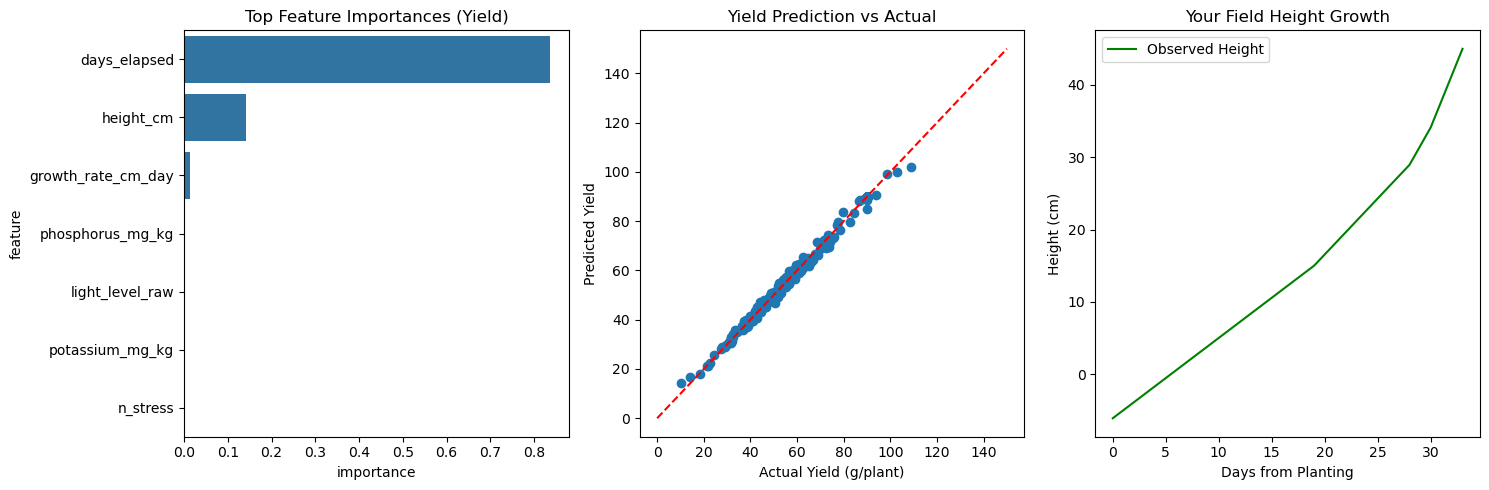

In [30]:
# Step 6: Visualization
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.barplot(data=importances.head(7), x='importance', y='feature')
plt.title('Top Feature Importances (Yield)')

plt.subplot(1, 3, 2)
plt.scatter(y_yield, rf_yield.predict(X))
plt.plot([0, 150], [0, 150], 'r--')
plt.xlabel('Actual Yield (g/plant)')
plt.ylabel('Predicted Yield')
plt.title('Yield Prediction vs Actual')

plt.subplot(1, 3, 3)
# Your field height growth
plt.plot(daily_df['days_elapsed'], daily_df['observed_height_cm'], 'g-', label='Observed Height')
plt.xlabel('Days from Planting')
plt.ylabel('Height (cm)')
plt.title('Your Field Height Growth')
plt.legend()

plt.tight_layout()
plt.show()

# To save model: import joblib; joblib.dump(rf_yield, 'amaranthus_yield_model_with_height.pkl')